# 02 · Cuts

Anna Preto — AstroDeep Project

The funnel of the eight cuts in recipe order, a gallery of rejects for each pixel cut with the reason drawn, the continuous quantities around each threshold, and a check of biases in magnitude, size and ellipticity.

Reads the products of the local pipeline (`dp2-cutouts config/local_demo.yaml all`). The outputs of this notebook show Rubin DP2 pixels: **never commit them** (clear the outputs before committing).

In [ ]:
from pathlib import Path
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dp2_cutouts.config import Config
from dp2_cutouts import viz

CONFIG = Path("../config/local_demo.yaml")
cfg = Config.load(CONFIG)
cc = cfg["cuts"]
table = pd.read_parquet(cfg.data("tables_and_stamps", "table.parquet"))
plt.rcParams["figure.dpi"] = 110
print(f"{len(table):,} objects in the catalogue")
stamps, smeta = viz.load_stamps(cfg)
bits = smeta["plane_bits"]
T = table.set_index("object_id")

## Funnel

,step,remaining,fraction removed
0,Rubin catalogue (copaings),"14,044",nan%
1,1 · Euclid: neither point-like nor spurious,"14,024",0.1%
2,2 · S_b = 0 and one-to-one,"10,916",22.2%
3,demo · inside the downloaded region,422,96.1%
4,3 · 29 px margin inside the patch,422,0.0%
5,4 · no unexposed pixel,419,0.7%
6,5 · no damaged pixel within k × ellipse,371,11.5%
7,6 · S/N(i) > 5,367,1.1%
8,7 · same pixel in all six bands,367,0.0%
9,8 · |Δe| between apertures ≤ 0.02,364,0.8%


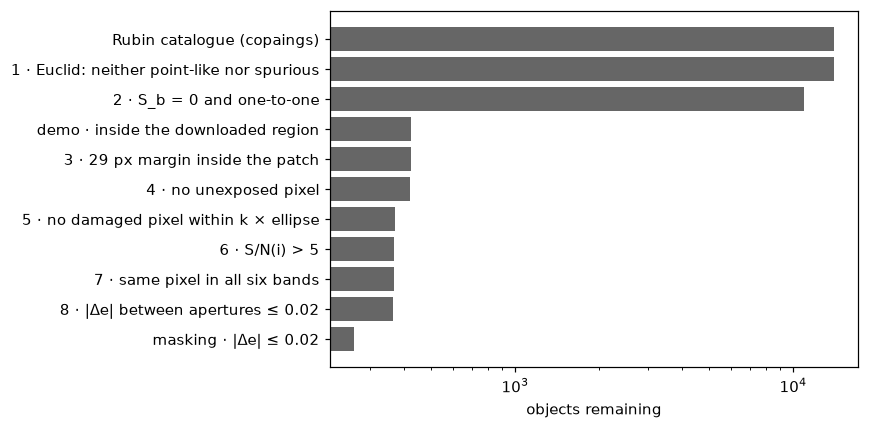

In [ ]:
f = viz.funnel(table)
display(f.style.format({"remaining": "{:,}", "fraction removed": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(f["step"][::-1], f["remaining"][::-1], color="0.4")
ax.set_xscale("log"); ax.set_xlabel("objects remaining")
plt.tight_layout()

From "inside the downloaded region" on, the percentages refer to targets that have pixels. Funnel restricted to these targets:

In [ ]:
f2 = viz.funnel(table, viz.STEPS[3:], start_mask=viz.stage_mask(table, "in_region"))
f2.style.format({"remaining": "{:,}", "fraction removed": "{:.1%}"})

,step,remaining,fraction removed
0,Rubin catalogue (copaings),422,nan%
1,3 · 29 px margin inside the patch,422,0.0%
2,4 · no unexposed pixel,419,0.7%
3,5 · no damaged pixel within k × ellipse,371,11.5%
4,6 · S/N(i) > 5,367,1.1%
5,7 · same pixel in all six bands,367,0.0%
6,8 · |Δe| between apertures ≤ 0.02,364,0.8%
7,masking · |Δe| ≤ 0.02,264,27.5%


## Continuous quantities around the thresholds

How many targets would pass at another threshold, without rebuilding anything.

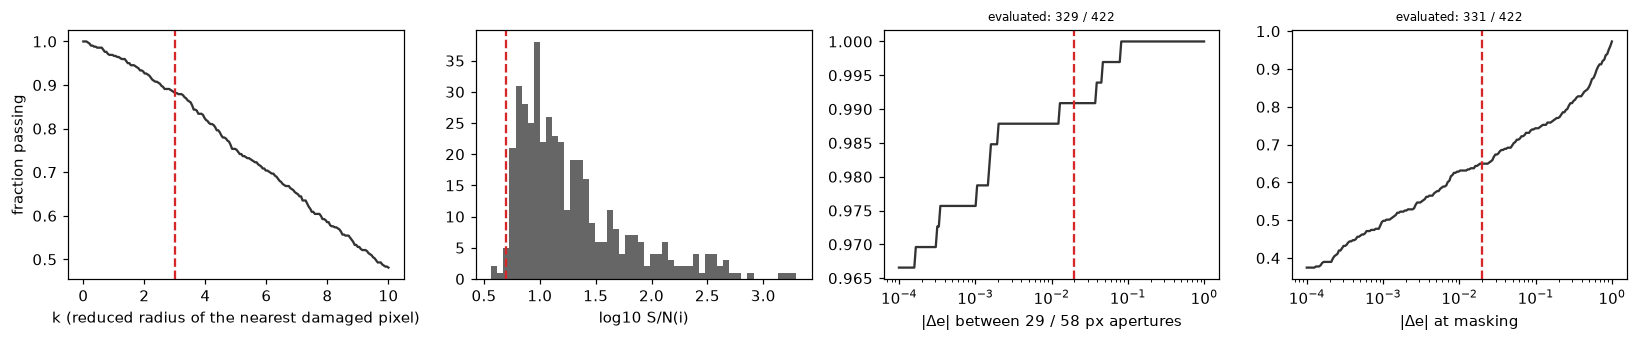

In [ ]:
R = table[table["in_region"]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
v = R["cut5_value"].replace(np.inf, 99)
k = np.linspace(0, 10, 200)
axes[0].plot(k, [(v > x).mean() for x in k], c="0.2"); axes[0].axvline(cc["k_ellipse"], c="C3", ls="--")
axes[0].set_xlabel("k (reduced radius of the nearest damaged pixel)"); axes[0].set_ylabel("fraction passing")
axes[1].hist(np.log10(R["cut6_value"].clip(lower=0.1)), bins=50, color="0.4"); axes[1].axvline(np.log10(cc["snr_min"]), c="C3", ls="--")
axes[1].set_xlabel("log10 S/N(i)")
for ax, col, name in [(axes[2], "cut8_value", "|Δe| between 29 / 58 px apertures"), (axes[3], "delta_e_mask", "|Δe| at masking")]:
    x = R[col].dropna()
    t = np.logspace(-4, 0, 200)
    ax.semilogx(t, [(x <= s).mean() for s in t], c="0.2"); ax.axvline(cc["delta_e_max"], c="C3", ls="--")
    ax.set_xlabel(name); ax.set_title(f"evaluated: {len(x)} / {len(R)}", fontsize=8)
plt.tight_layout()

## Cut 4: unexposed pixels (in red)

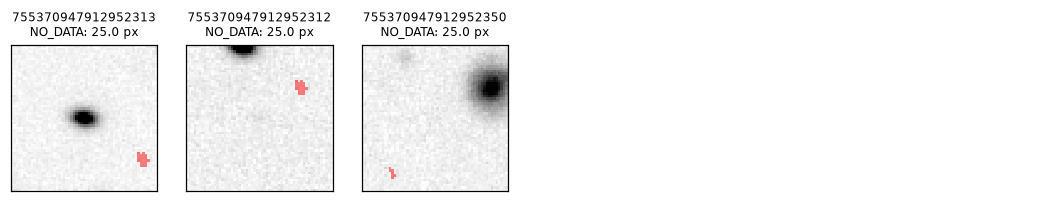

In [ ]:
rej = R[~R["cut4_pass"].astype(bool)]
fig, axes = viz.grid(max(len(rej), 1))
for ax, row in zip(axes, rej.itertuples()):
    s = stamps[row.object_id]
    viz.show(ax, s["flux_raw"][3], f"{row.object_id}\nNO_DATA: {row.cut4_value} px")
    viz.overlay(ax, np.any(s["maskbits"] & bits["NO_DATA"], axis=0), "red")

## Cut 5: damaged pixels (colour by plane) and k × ellipse (dashed)

{'SATURATED': 'red', 'COSMIC_RAY': 'orange', 'INTERPOLATED': 'cyan', 'DETECTION_EDGE': 'magenta'}


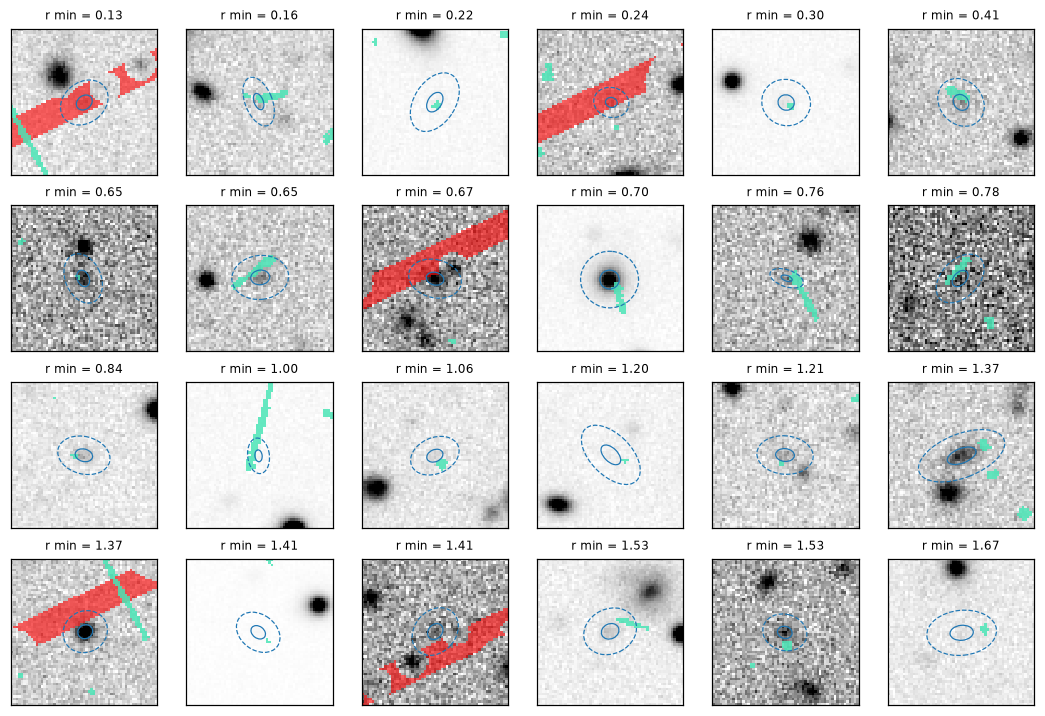

In [ ]:
colors = {"SATURATED": "red", "COSMIC_RAY": "orange", "INTERPOLATED": "cyan", "DETECTION_EDGE": "magenta"}
rej = R[~R["cut5_pass"].astype(bool)].sort_values("cut5_value").head(24)
fig, axes = viz.grid(len(rej))
for ax, row in zip(axes, rej.itertuples()):
    s = stamps[row.object_id]
    viz.show(ax, s["flux_raw"][3], f"r min = {row.cut5_value:.2f}")
    for p, col in colors.items():
        viz.overlay(ax, np.any(s["maskbits"] & bits[p], axis=0), col, 0.6)
    xc, yc = viz.stamp_center(row)
    viz.draw_ellipse(ax, xc, yc, row.ellipse_a, row.ellipse_b, row.ellipse_theta, 1, ec="C0", lw=0.8)
    viz.draw_ellipse(ax, xc, yc, row.ellipse_a, row.ellipse_b, row.ellipse_theta, cc["k_ellipse"], ec="C0", lw=0.8, ls="--")
print({p: c for p, c in colors.items()})

## Cut 8: is the 59 px stamp large enough?

A diagnostic stamp **twice as large** (117 × 117 px) is cut around the target, masked the same way, and the target shape is measured in two circular apertures: 29 px radius (the dataset stamp) and 58 px. If the two measurements differ by more than 0.02, light from beyond the stamp distorts the target.

**Legend** — title: |Δe| between the two apertures; **red circles**: 29 and 58 px apertures; **dotted square**: the 59 px dataset stamp; **blue ellipse**: the target; **green**: pixels replaced by sky (masked companions).

The measurement (galsim adaptive moments) only looks at pixels close to the galaxy: for most targets, the 29 px aperture already holds all the weight and the offset is zero. The largest offsets, often very faint targets:

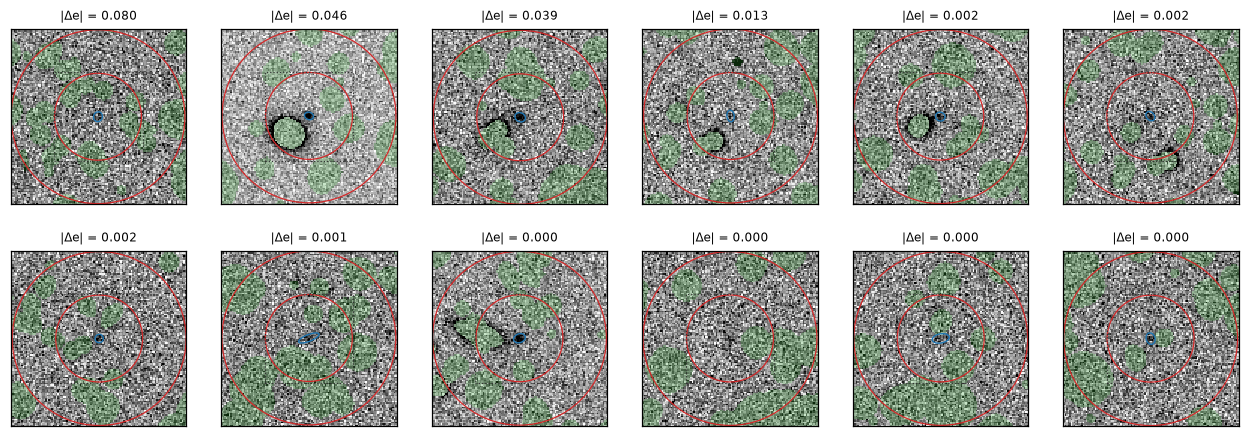

In [ ]:
from matplotlib.patches import Rectangle
top = R[R["cut8_evaluated"].astype(bool)].sort_values("cut8_value", ascending=False).head(12)
fig, axes = viz.grid(len(top), ncols=6, size=2.4)
n, nd = smeta["stamp_px"], smeta["diag_px"]
for ax, row in zip(axes, top.itertuples()):
    s = stamps[row.object_id]
    if "diag_flux" not in s:
        continue
    viz.show(ax, s["diag_flux"], f"|Δe| = {row.cut8_value:.3f}")
    viz.overlay(ax, s["diag_need"], "C2", 0.25)
    xc, yc = viz.stamp_center(row, n=nd)
    for r_ in cc["aperture_radii"]:
        viz.draw_circle(ax, xc, yc, r_, ec="C3", lw=0.8)
    h = (nd - n) // 2
    ax.add_patch(Rectangle((h - 0.5, h - 0.5), n, n, fill=False, ec="0.2", ls=":", lw=0.8))
    viz.draw_ellipse(ax, xc, yc, row.ellipse_a, row.ellipse_b, row.ellipse_theta, ec="C0", lw=0.9)

## Biases: shape measurement must not sort the galaxies

Distributions after cut 2 (targets in the region), then in the final dataset. Kolmogorov–Smirnov distance on |e| to compare with the noise floor.

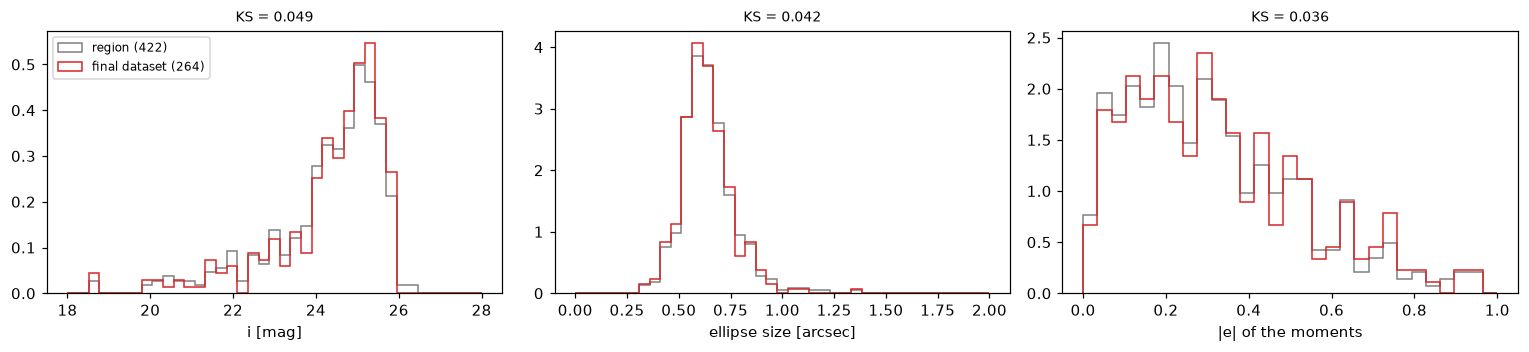

In [ ]:
from scipy.stats import ks_2samp
a_ = R
b_ = table[viz.stage_mask(table, "mask")]
size = lambda d: np.sqrt(d["ellipse_a"] * d["ellipse_b"]) * 0.2
emod = lambda d: np.hypot(d["e1_moments"], d["e2_moments"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for ax, f_, name, bins in [(axes[0], lambda d: d["i_cModel_mag"], "i [mag]", np.linspace(18, 28, 40)),
                           (axes[1], size, "ellipse size [arcsec]", np.linspace(0, 2, 40)),
                           (axes[2], emod, "|e| of the moments", np.linspace(0, 1, 30))]:
    ax.hist(f_(a_), bins=bins, histtype="step", density=True, label=f"region ({len(a_)})", color="0.5")
    ax.hist(f_(b_), bins=bins, histtype="step", density=True, label=f"final dataset ({len(b_)})", color="C3")
    ks = ks_2samp(f_(a_).dropna(), f_(b_).dropna())
    ax.set_xlabel(name); ax.set_title(f"KS = {ks.statistic:.3f}", fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()